# **Logistic Regression versus Bayes Classifier**

***[Discriminative vs Generative Models]
I Load the breast cancer dataset via load breast cancer in sklearn.datasets, import LogisticRegression from sklearn. For the Bayes classifier consider the Naive Bayes variant (with- out shared covariance) as well as the variants with full covariance (shared and not shared). Perform a training/test split (with train size equal to 0.8) and report which of the models performs best in terms of train and test performance.***



In [ ]:
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import multivariate_normal

In [ ]:
class BayesianClassifier:

    def __init__(self, shared_cov=True, cond_ind=True):
        self.shared_cov=shared_cov
        self.cond_ind=cond_ind

    def fit(self, x, y):
        self.classes_, class_counts = np.unique(y, return_counts=True)
        self.n_ , self.p_ = x.shape
        self.k_ = len(self.classes_)
        self.cond_means_ = np.zeros(shape=(self.k_, self.p_))
        self.cond_covs_ = np.zeros(shape=(self.k_, self.p_, self.p_))

        self.class_priors_ = class_counts/len(y)
        for c in range(self.k_):
            c_rows = y==c
            self.cond_means_[c, :] = x[c_rows].mean(axis=0)
            if self.cond_ind:
                np.fill_diagonal(self.cond_covs_[c, :, :], x[c_rows].var(axis=0))
            else:
                self.cond_covs_[c, :, :] = np.cov(x[c_rows].T, bias=True)

        if self.shared_cov:
            shared_cov = np.moveaxis(self.cond_covs_, 0, -1).dot(self.class_priors_)
            self.cond_covs_[:] = shared_cov

        return self

    def predict_proba(self, x):
        m, _ = x.shape
        cond_probs = np.zeros(shape=(m, self.k_))
        for c in range(self.k_):
            # find p(x | c_k)
            # singular covariance matrices could happen (e.g., through inaccurate estimation)
            cond_probs[:, c] = multivariate_normal.pdf(x,
                                                       self.cond_means_[c],
                                                       self.cond_covs_[c],
                                                       allow_singular=True)
        # find marginal probabilities p(x) by summing all the conditionals weighted by the priors
        marginal_probs = cond_probs.dot(self.class_priors_)

        # find probability vector (p(c1 | x), ..., p(ck | x)) via p(ci | x)=p(x | ci) / p(x)
        # however, p(x) might have been rounded to 0
        # thus, compute via case distinction
        probs = np.divide((cond_probs*self.class_priors_).T,
                          marginal_probs,
                          where=marginal_probs>0, out=np.zeros(shape=(self.k_, m))).T
        return probs

    def predict(self, x):
        return np.argmax(self.predict_proba(x), axis=1)

    def decision_function(self, x):
        probs = self.predict_proba(x)
        if self.k_ == 2:
            return np.log(probs[:, 1]/probs[:, 0])
        else:
            res = np.zeros(len(x), self.k_)
            for c in range(self.k_):
                res[:, c]=np.log(probs[:, c]/(1-probs[:, c]))
            return res

    def generate(self, n, c, random_state=None):
        return multivariate_normal.rvs(self.cond_means_[c], self.cond_covs_[c], size=n, random_state=random_state)

In [ ]:
data = load_breast_cancer()
X, y = data.data, data.target
X_train, X_test, y_train, y_test = train_test_split(X, y, train_size=0.8, random_state=42)

In [ ]:

clf = LogisticRegression(max_iter=10000)
clf.fit(X_train, y_train)

log_train_acc = clf.score(X_train, y_train)
log_test_acc = clf.score(X_test, y_test)


In [ ]:
nb_unshared = BayesianClassifier(shared_cov=False, cond_ind=True)
nb_unshared.fit(X_train, y_train)

nb_train_acc = np.mean(nb_unshared.predict(X_train) == y_train)
nb_test_acc = np.mean(nb_unshared.predict(X_test) == y_test)


In [ ]:
full_shared = BayesianClassifier(shared_cov=True, cond_ind=False)
full_shared.fit(X_train, y_train)

fs_train_acc = np.mean(full_shared.predict(X_train) == y_train)
fs_test_acc = np.mean(full_shared.predict(X_test) == y_test)


In [ ]:
full_unshared = BayesianClassifier(shared_cov=False, cond_ind=False)
full_unshared.fit(X_train, y_train)

fu_train_acc = np.mean(full_unshared.predict(X_train) == y_train)
fu_test_acc = np.mean(full_unshared.predict(X_test) == y_test)


In [ ]:
print(f"Logistic Regression:        Train accuracy={log_train_acc:.4f}, Testaccuracy={log_test_acc:.4f}")
print(f"Naive Bayes (Unshared):     Train accuracy={nb_train_acc:.4f}, Testaccuracy={nb_test_acc:.4f}")
print(f"Full Cov (Shared):          Train accuracy={fs_train_acc:.4f}, Testaccuracy={fs_test_acc:.4f}")
print(f"Full Cov (Unshared):        Train accuracy={fu_train_acc:.4f}, Testaccuracy={fu_test_acc:.4f}")



Logistic Regression:        Train accuracy=0.9626, Testaccuracy=0.9561
Naive Bayes (Unshared):     Train accuracy=0.9275, Testaccuracy=0.9561
Full Cov (Shared):          Train accuracy=0.9626, Testaccuracy=0.9561
Full Cov (Unshared):        Train accuracy=0.9429, Testaccuracy=0.9211


In terms of best train and test performance.


Logistic Regression:Train accuracy=0.9626, Testaccuracy=0.9561

Full Cov (Shared):Train accuracy=0.9626, Testaccuracy=0.9561

***an experiment where we test the performance for increasing training sizes of
N = 5, 10, . . . , 500. For each N sample 10 training sets of the corresponding size, fit all models, and record training and test errors.***


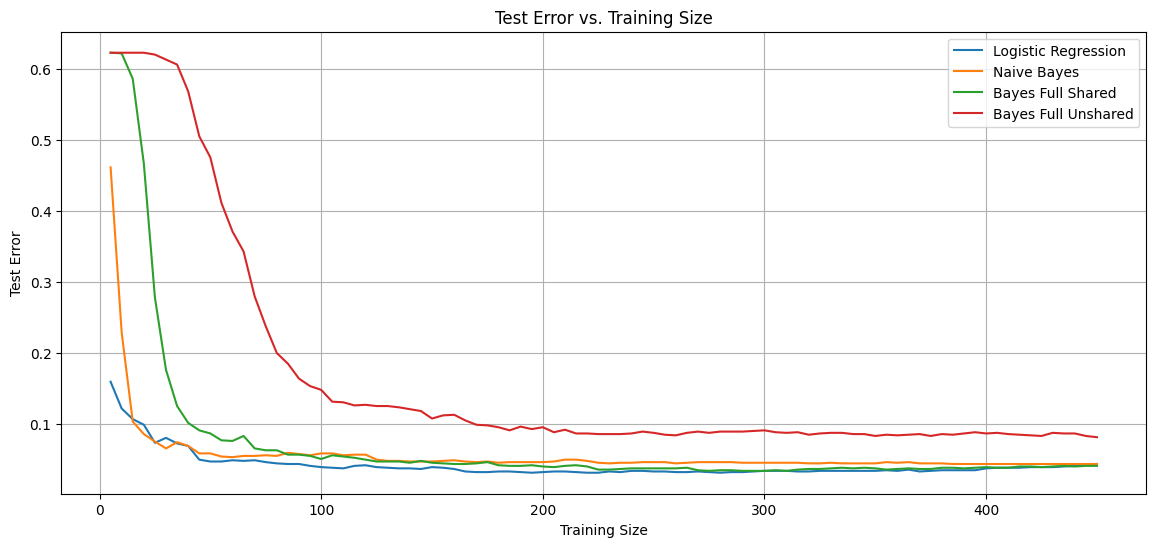

In [ ]:
data = load_breast_cancer()
X_full, y_full = data.data, data.target

# Fix test set once (20%)
X_pool, X_test, y_pool, y_test = train_test_split(X_full, y_full, test_size=0.2, random_state=42)

# Training sizes to test
train_sizes = np.arange(5, len(X_pool), 5)  # Prevents overflow
repeats = 10

# Store errors: [#sizes, #models, train/test]
errors = np.zeros((len(train_sizes), 4, 2))

for i, train_size in enumerate(train_sizes):
    train_errors = np.zeros((repeats, 4))
    test_errors = np.zeros((repeats, 4))

    for r in range(repeats):
        # Sample a training set of size `train_size`
        X_train, _, y_train, _ = train_test_split(
            X_pool, y_pool, train_size=train_size, shuffle=True, random_state=r
        )

        # Initialize models
        models = [
            LogisticRegression(max_iter=10000),
            BayesianClassifier(shared_cov=False, cond_ind=True),
            BayesianClassifier(shared_cov=True, cond_ind=False),
            BayesianClassifier(shared_cov=False, cond_ind=False)
        ]

        for j, model in enumerate(models):
            model.fit(X_train, y_train)
            pred_train = model.predict(X_train)
            pred_test = model.predict(X_test)

            train_errors[r, j] = np.mean(pred_train != y_train)
            test_errors[r, j] = np.mean(pred_test != y_test)

    # Store mean errors for this training size
    errors[i, :, 0] = train_errors.mean(axis=0)  # train error
    errors[i, :, 1] = test_errors.mean(axis=0)   # test error

# Plotting the test error curves
model_names = ['Logistic Regression', 'Naive Bayes', 'Bayes Full Shared', 'Bayes Full Unshared']
colors = ['tab:blue', 'tab:orange', 'tab:green', 'tab:red']

plt.figure(figsize=(14, 6))
for j in range(4):
    plt.plot(train_sizes, errors[:len(train_sizes), j, 1], label=model_names[j], color=colors[j])
plt.xlabel("Training Size")
plt.ylabel("Test Error")
plt.title("Test Error vs. Training Size")
plt.legend()
plt.grid(True)
plt.show()

***suitable plots that compare the mean train and test performances of all models as a function of training size.***

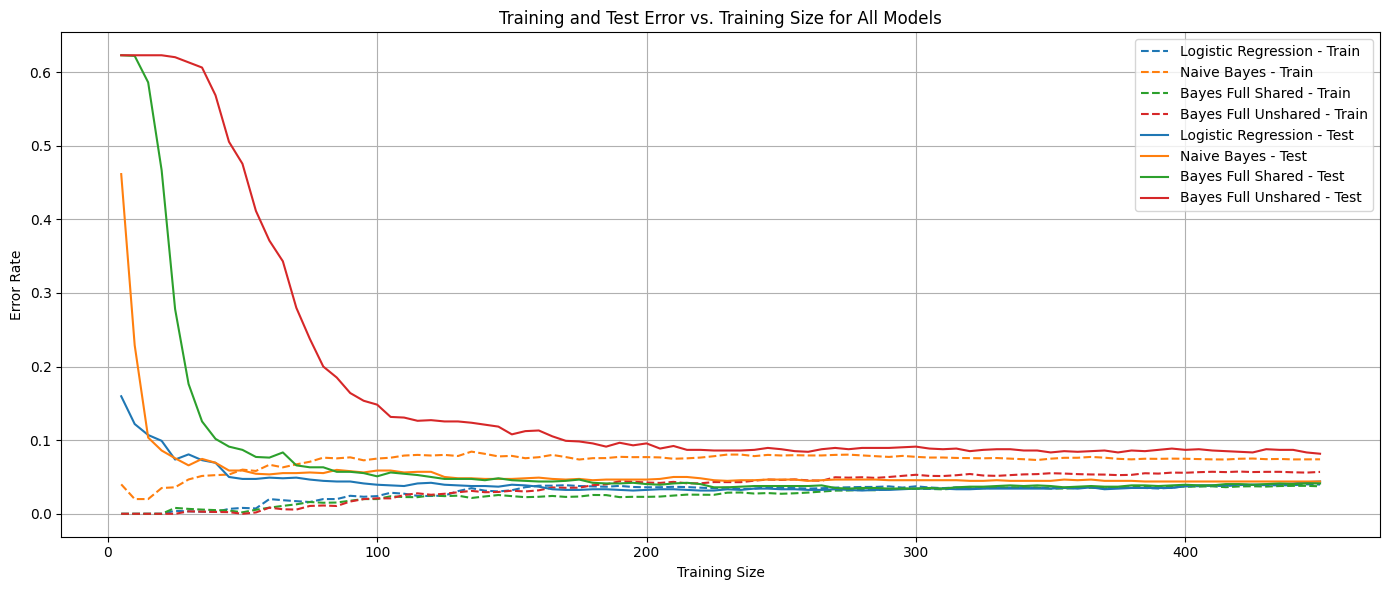

In [ ]:


model_names = ['Logistic Regression', 'Naive Bayes', 'Bayes Full Shared', 'Bayes Full Unshared']
colors = ['tab:blue', 'tab:orange', 'tab:green', 'tab:red']

plt.figure(figsize=(14, 6))

# Plot mean train errors
for j in range(4):
    plt.plot(train_sizes, errors[:, j, 0], linestyle='--', color=colors[j], label=f"{model_names[j]} - Train")

# Plot mean test errors
for j in range(4):
    plt.plot(train_sizes, errors[:, j, 1], linestyle='-', color=colors[j], label=f"{model_names[j]} - Test")

plt.xlabel("Training Size")
plt.ylabel("Error Rate")
plt.title("Training and Test Error vs. Training Size for All Models")
plt.legend(loc='upper right')
plt.grid(True)
plt.tight_layout()
plt.show()


Looking at the graph showing "Training and Test Error vs. Training Size for All Models," I'll analyze the performance trends and provide insights for each of your questions.

**Logistic Regression:**
- Training error (dashed blue): Starts near zero and gradually increases slightly as training size grows
- Test error (solid blue): Starts high (~0.16) and decreases quickly, stabilizing around 0.04 with larger training sets

**Naive Bayes:**
- Training error (dashed orange): Starts low, increases slightly, then stabilizes around 0.07
- Test error (solid orange): Starts very high (~0.45), drops rapidly until about 50 training samples, then stabilizes around 0.05-0.06

**Bayes Full Shared:**
- Training error (dashed green): Begins near zero and gradually increases to around 0.03
- Test error (solid green): Starts high (~0.62), decreases rapidly until about 75 samples, then stabilizes around 0.04

**Bayes Full Unshared:**
- Training error (dashed red): Remains extremely low throughout
- Test error (solid red): Starts very high (~0.62), decreases more gradually than other models, continues improving until about 150 samples, then stabilizes around 0.08-0.09

**the classifier which is best suited when the training set is small, and which is best suited when the training set is big?**

**For small training sets:**
- Logistic Regression performs best with limited data (lowest test error when training size < 25)
- Naive Bayes also performs reasonably well with small data

**For large training sets:**
- With sufficient data (>150 samples), Logistic Regression, Naive Bayes, and Bayes Full Shared all converge to similar test performance
- Bayes Full Shared slightly outperforms the others when the training set is very large (>300 samples)
- Bayes Full Unshared consistently shows the highest test error even with large training sets

**Justification and possible reasons:**

**Logistic Regression:**
- Has relatively few parameters to learn, making it less prone to overfitting with small datasets
- Makes fewer assumptions about data distributions compared to Bayesian methods
- The gradual increase in training error with more data suggests it might be slightly underfitting

**Naive Bayes:**
- Makes strong independence assumptions that may not hold in reality
- Requires less data to estimate its parameters due to these simplifying assumptions
- The gap between training and test error indicates some bias in the model

**Bayes Full Shared:**
- More complex than Naive Bayes but with parameter sharing to reduce overfitting
- Requires more data than simpler models to show its advantages
- Eventually performs best as it balances flexibility and constraint

**Bayes Full Unshared:**
- Most complex model with the most parameters to learn
- Shows classic signs of overfitting: near-zero training error but higher test error
- The large gap between its training and test error suggests it memorizes training data rather than generalizing
- Needs substantially more data to overcome its tendency to overfit

The performance patterns align with the bias-variance tradeoff: simpler models (Logistic Regression) perform better with limited data by avoiding overfitting, while more expressive models can potentially capture more complex patterns but require larger datasets to generalize well.